## Dog breeds classifier.
In this tasks you are supposed to build dog breeds classifier.
You may use materials of previous classes, chat gpt, anything.

Just get the maximum accuracy.

In [16]:
from glob import glob
import os
import numpy as np
import cv2
import matplotlib.pyplot as plt
import pickle as pkl
import uuid
from time import time

### Download the data

In [13]:
# Google golab or in any Unix OS you may do that:
!wget -O dogdata.zip https://www.dropbox.com/scl/fi/bokia8qstdekcyjqig1c5/dogdata.zip?rlkey=esrxurxfr4fe50duknmab979a&st=aqjo6u4r&dl=1 
!unzip -q dogdata.zip -d dogdata
data_path = './dogdata'
# Or, you may download and extract file manually: https://www.dropbox.com/scl/fi/bokia8qstdekcyjqig1c5/dogdata.zip
# And provide the path to extracted data here:
# data_path = #'D:/Data/dogs'

unzip:  cannot find or open dogdata.zip, dogdata.zip.zip or dogdata.zip.ZIP.


### Read labels and filenames

In [7]:
fns = []
y = []
for lp in glob(f'{data_path}/train/*'):
    label = os.path.basename(lp)
    for fn in glob(f'{lp}/*'):
        fns.append(fn)
        y.append(label)
fns = np.array(fns)
y = np.array(y)

fns_submit = glob(f'{data_path}/test/*')

### Here are several examples:

In [8]:
for label in list(set(y))[:5]:
    print(label)
    img = cv2.imread(fns[y == label][0])
    plt.imshow(img[:,:,::-1])
    plt.show()

# Your code goes here:

## Check the Data

train: 9022  test: 1200  classes: 120
min     56.0
50%     72.0
max    116.0
Name: count, dtype: float64


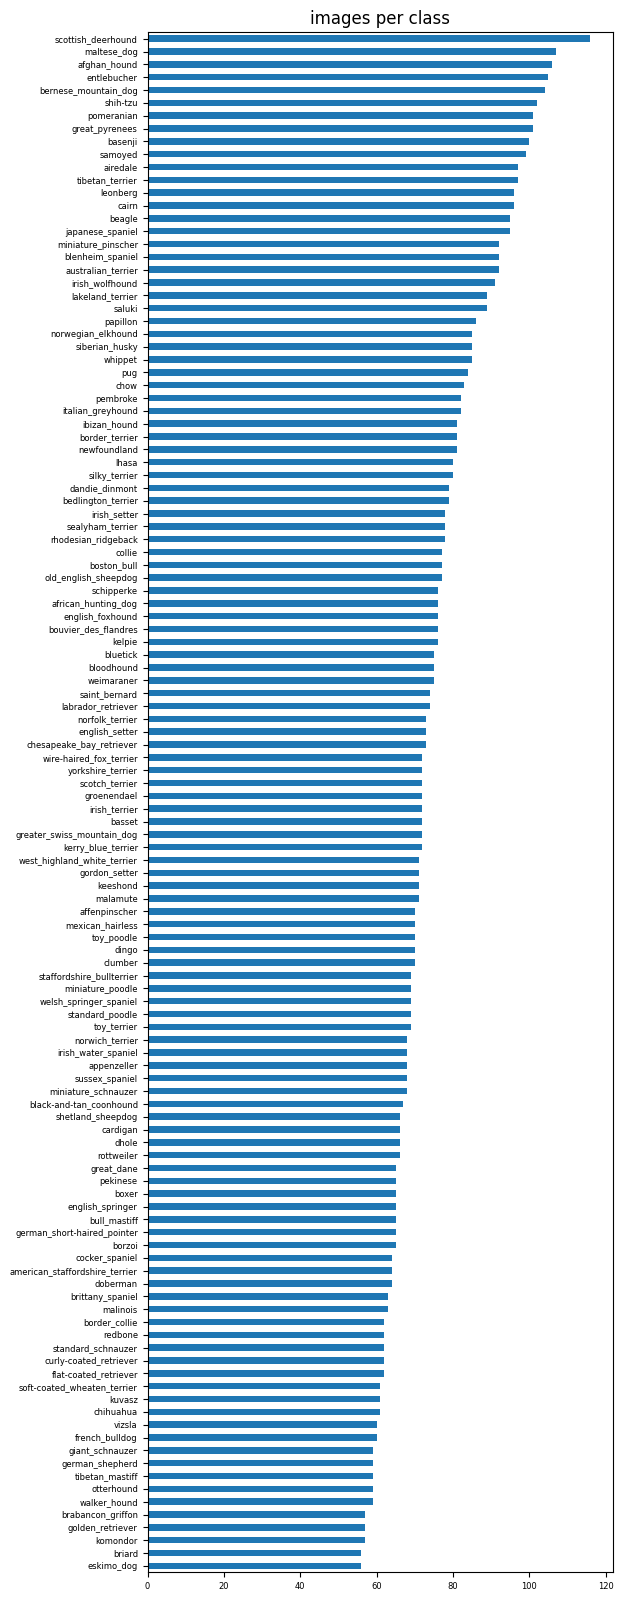

In [15]:
import pandas as pd
from PIL import Image

# 1) How many images / classes, and are classes balanced?
classes = np.unique(y)
counts = pd.Series(y).value_counts()
print(f'train: {len(fns)}  test: {len(fns_submit)}  classes: {len(classes)}')
print(counts.describe()[['min', '50%', 'max']])

counts.sort_values().plot.barh(figsize=(6, 20), fontsize=6, title='images per class')
plt.show()

split            test    train
w      count  1200.00  9022.00
       mean    444.70   443.15
       std     151.55   152.54
       min     110.00    97.00
       25%     356.25   360.00
       50%     500.00   500.00
       75%     500.00   500.00
       max    2560.00  3264.00
h      count  1200.00  9022.00
       mean    387.06   386.71
       std     136.17   129.24
       min     122.00   102.00
       25%     333.00   333.00
       50%     375.00   375.00
       75%     450.00   453.75
       max    1920.00  2562.00
aspect count  1200.00  9022.00
       mean      1.19     1.19
       std       0.30     0.30
       min       0.44     0.39
       25%       0.93     0.93
       50%       1.33     1.33
       75%       1.34     1.34
       max       2.23     2.60
split  mode
test   RGB     1200
train  RGB     9022
Name: count, dtype: int64


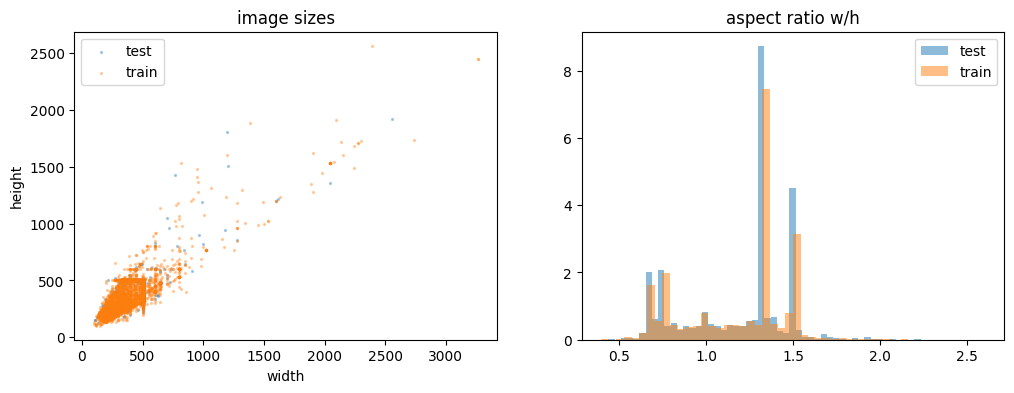

In [16]:
# 2) Image sizes, aspect ratio, color mode, broken files (train vs test)
def img_info(fn):
    try:
        with Image.open(fn) as im:  # reads header only -> fast
            return im.size[0], im.size[1], im.mode
    except Exception:
        return None, None, 'broken'

info = pd.DataFrame([img_info(f) for f in fns] + [img_info(f) for f in fns_submit], columns=['w', 'h', 'mode'])

info['split'] = ['train'] * len(fns) + ['test'] * len(fns_submit)
info['aspect'] = info.w / info.h

print(info.groupby('split')[['w', 'h', 'aspect']].describe().T.round(2))
print(info.groupby('split')['mode'].value_counts())  # non-RGB -> need .convert('RGB')

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for s, d in info.groupby('split'):
    ax[0].scatter(d.w, d.h, s=2, alpha=0.3, label=s)
    ax[1].hist(d.aspect, bins=50, alpha=0.5, density=True, label=s)
ax[0].set(xlabel='width', ylabel='height', title='image sizes'); ax[0].legend()
ax[1].set(title='aspect ratio w/h'); ax[1].legend()
plt.show()

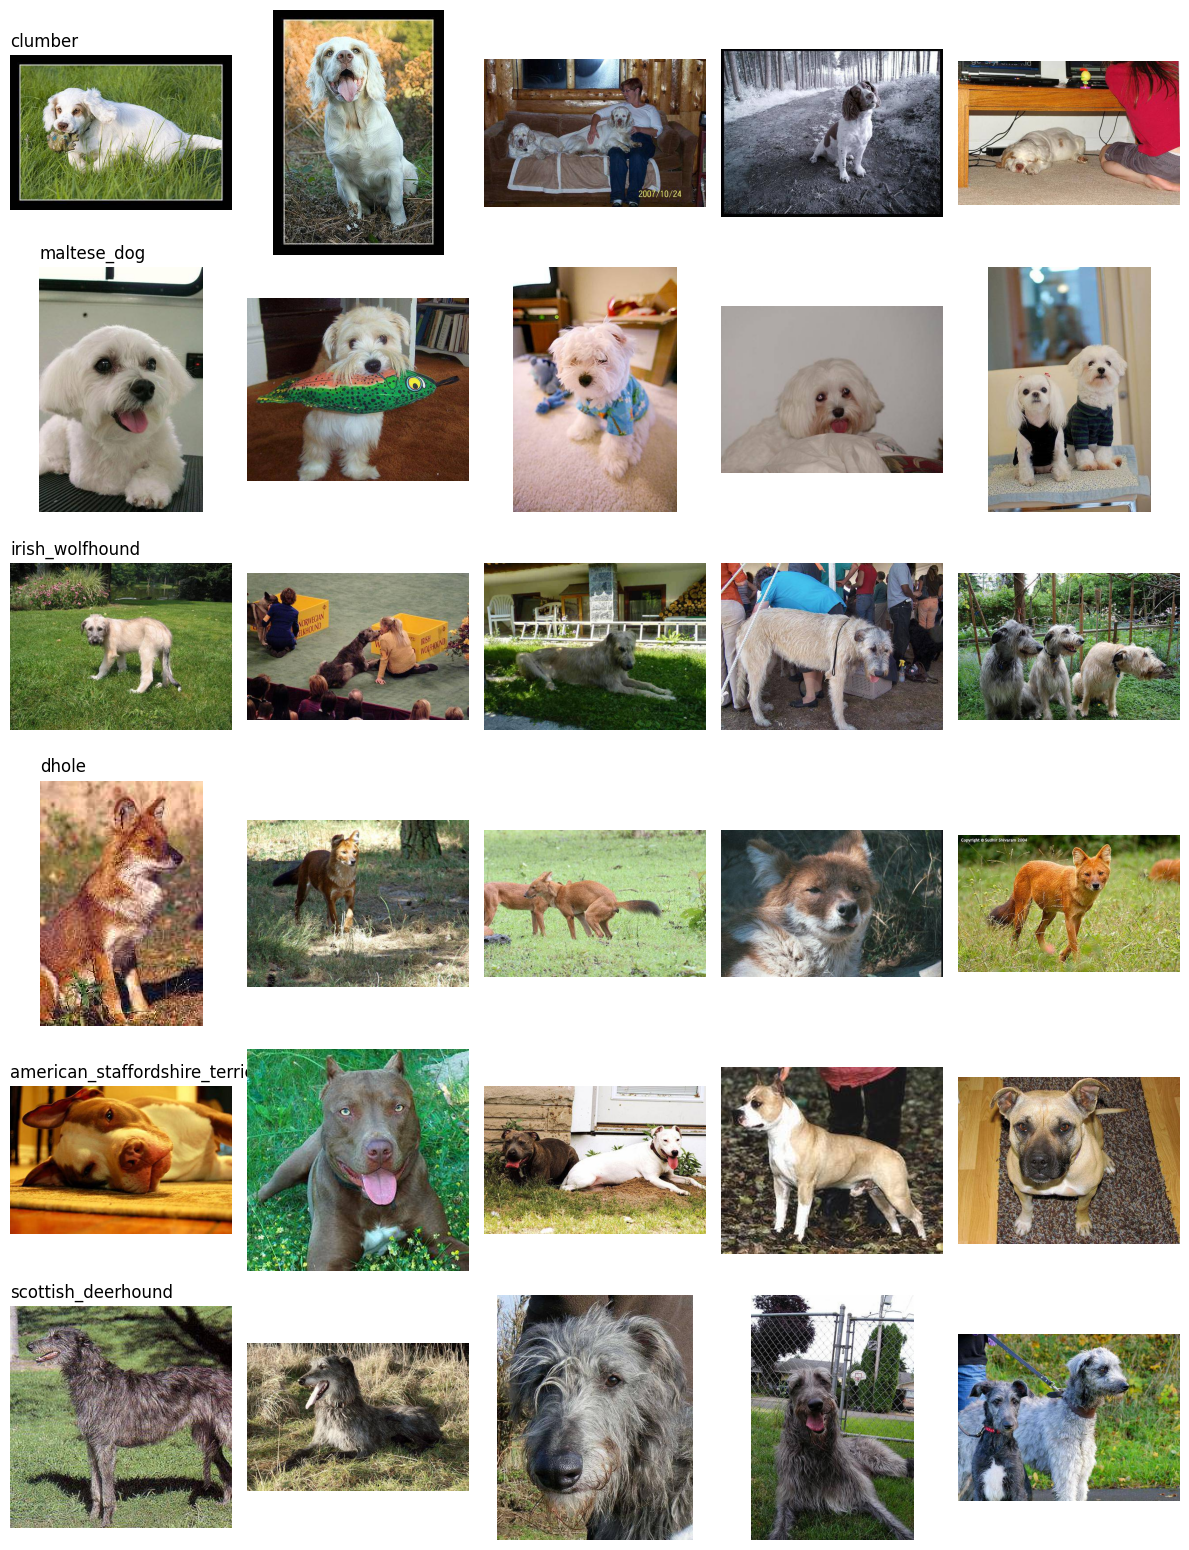

In [17]:
# 3) Eyeball: 5 random images for 6 random breeds (dog size, background, other objects/people, crops)
rng = np.random.default_rng(0)
show = rng.choice(classes, 6, replace=False)
fig, axes = plt.subplots(len(show), 5, figsize=(12, 2.6 * len(show)))
for row, label in zip(axes, show):
    for ax, fn in zip(row, rng.choice(fns[y == label], 5, replace=False)):
        ax.imshow(Image.open(fn).convert('RGB')); ax.axis('off')
    row[0].set_title(label, loc='left')
plt.tight_layout(); plt.show()

## Resnet50_pretain

torch.Size([64, 3, 224, 224]) torch.float32 tensor([ 70,  17,  23,  90, 112,  43, 115, 113])


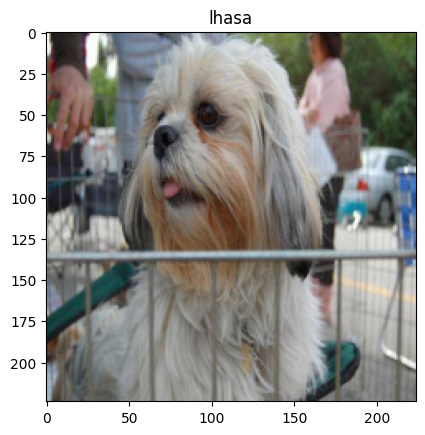

In [51]:
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import torch
from concurrent.futures import ThreadPoolExecutor

from sklearn.model_selection import train_test_split

# map class2idx
cls2idx = {c: i for i, c in enumerate(classes)}
y_idx = np.array([cls2idx[c] for c in y])


X_train, X_val, y_train, y_val = train_test_split(fns, y_idx, stratify=y_idx, test_size=0.2, random_state=67)

MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
train_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD),
])
val_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD),
])

def load_rgb(fn):
    return Image.open(fn).convert('RGB')

if 'IMG_CACHE' not in globals():  # skip the ~20 s preload when re-running this cell
    with ThreadPoolExecutor(4) as ex:  # PIL releases the GIL while decoding, so threads use both cores
        IMG_CACHE = dict(zip(fns, ex.map(load_rgb, fns)))
    print(f"cached {len(IMG_CACHE)} images in RAM: {sum(im.width * im.height * 3 for im in IMG_CACHE.values()) / 1e9:.1f} GB")

class DogDataset(Dataset):
    def __init__(self, fns, labels=None, tf=None):
        self.X = fns
        self.labels = labels
        self.tf = tf

    def __len__(self):
        return len(self.X)

    def __getitem__(self, i):
        fn = self.X[i]
        img = IMG_CACHE[fn] if fn in IMG_CACHE else load_rgb(fn)
        label = -1 if self.labels is None else self.labels[i]

        if self.tf is not None:
            img = self.tf(img)

        return img, label  

BS = 64
LOADER_OPTS = dict(num_workers=2, pin_memory=True, persistent_workers=True)
train_dl = DataLoader(DogDataset(X_train, y_train, train_tf), batch_size=BS, shuffle=True, **LOADER_OPTS)
val_dl = DataLoader(DogDataset(X_val, y_val, val_tf), batch_size=BS, **LOADER_OPTS)
test_dl = DataLoader(DogDataset(fns_submit, None, val_tf), batch_size=BS, num_workers=2)

# --- 5) Sanity check: shapes + one image undone back to normal colors ---
xb, yb = next(iter(train_dl))
print(xb.shape, xb.dtype, yb[:8])  # expect torch.Size([64, 3, 224, 224]) torch.float32
img = xb[0].permute(1, 2, 0) * torch.tensor(STD) + torch.tensor(MEAN)
plt.imshow(img.clamp(0, 1)); plt.title(classes[yb[0].item()]); plt.show()  # dog looks normal + title matches?
    

In [52]:
from time import time
from tqdm import tqdm
import torch.nn as nn

LOSS_FN = nn.CrossEntropyLoss() 

def train_one_epoch(model, dl, opt, scaler):
    device = next(model.parameters()).device
    start_time = time()

    model.train()
    total_loss = 0
    for xb, yb in tqdm(dl, desc="training..."):
        xb = xb.to(device, non_blocking=True, memory_format=torch.channels_last)
        yb = yb.to(device, non_blocking=True)

        opt.zero_grad()
        with torch.autocast(device.type, dtype=torch.float16, enabled=device.type == 'cuda'):
            logits = model(xb)
            loss = LOSS_FN(logits, yb)
        scaler.scale(loss).backward()  # scaling keeps small fp16 gradients from rounding to zero
        scaler.step(opt)
        scaler.update()

        total_loss += loss.item()
    elapsed = time() - start_time

    print(f"train loss: {total_loss / len(dl):.3f} used {elapsed:.0f}s")
    return total_loss / len(dl)

@torch.no_grad()
def evaluate_model(model, dl):
    device = next(model.parameters()).device
    model.eval()
    total_loss, correct = 0, 0
    for xb, yb in tqdm(dl, desc="evaluating..."):
        xb = xb.to(device, non_blocking=True, memory_format=torch.channels_last)
        yb = yb.to(device, non_blocking=True)

        with torch.autocast(device.type, dtype=torch.float16, enabled=device.type == 'cuda'):
            logits = model(xb)
            loss = LOSS_FN(logits, yb)
        total_loss += loss.item()

        correct += (logits.argmax(1) == yb).sum().item()
    acc = correct / len(dl.dataset)

    print(f"val loss: {total_loss / len(dl):.3f} val acc: {acc:.4f}")
    return total_loss / len(dl), acc


In [50]:
import copy
import hashlib, json
from torch.utils.tensorboard import SummaryWriter

# AI
CKPT_DIR = 'checkpoints'
os.makedirs(CKPT_DIR, exist_ok=True)

def loader_key(dl):
    return dict(tf=repr(dl.dataset.tf), batch_size=dl.batch_size,
                files=hashlib.md5(''.join(dl.dataset.X).encode()).hexdigest())

def run_experiment(name, model, train_dl, val_dl, epochs, lr, version=1, patience=None):
    """One Experiment: train the model's trainable weights, keep the best epoch by val accuracy, cache it.
    Same name + settings + training data -> load the Checkpoint instead of training. Returns val accuracy.
    Code edits are not part of the key: bump `version` after changing the training code.
    patience: stop after this many epochs without a val accuracy gain (None = run all epochs).
    Logs train/val loss and val accuracy per epoch to TensorBoard under runs/."""
    # fp16 training was added later without bumping version on purpose: weights differ only by rounding, fp32 checkpoints stay valid
    key = dict(name=name, epochs=epochs, lr=lr, data=loader_key(train_dl), version=version)
    if patience is not None:  # added only when set, so Checkpoints trained before early stopping keep their key
        key['patience'] = patience
    path = os.path.join(CKPT_DIR, f"{name}_{hashlib.md5(json.dumps(key, sort_keys=True).encode()).hexdigest()[:10]}.pt")
    device = next(model.parameters()).device
    model.to(memory_format=torch.channels_last)  # match the channels_last inputs in train/evaluate
    if os.path.exists(path):
        model.load_state_dict(torch.load(path, map_location=device))
        print(f"cache hit: loaded {path}, training skipped")
        return evaluate_model(model, val_dl)[1]

    # each param in exactly one group: fc is the new head (lr 1e-3), the rest is the pretrained backbone (`lr`).
    # frozen backbone -> empty backbone group, which AdamW accepts.
    head = list(model.fc.parameters())
    backbone = [p for n, p in model.named_parameters() if p.requires_grad and not n.startswith('fc.')]
    opt = torch.optim.AdamW([
        {"params": backbone, "lr": lr},
        {"params": head, "lr": 1e-3},
    ], weight_decay=0.05)
    scaler = torch.amp.GradScaler(device.type, enabled=device.type == 'cuda')
    best_acc, best_state, bad_epochs = -1.0, None, 0
    log_dir = os.path.join('runs', os.path.splitext(os.path.basename(path))[0])  # one log dir per Checkpoint
    with SummaryWriter(log_dir) as writer:
        for epoch in range(epochs):
            print(f"epoch {epoch + 1}/{epochs}")
            train_loss = train_one_epoch(model, train_dl, opt, scaler)
            val_loss, acc = evaluate_model(model, val_dl)
            writer.add_scalar('loss/train', train_loss, epoch)
            writer.add_scalar('loss/val', val_loss, epoch)
            writer.add_scalar('acc/val', acc, epoch)
            if acc > best_acc:
                best_acc, best_state, bad_epochs = acc, copy.deepcopy(model.state_dict()), 0
            else:
                bad_epochs += 1
                if patience is not None and bad_epochs >= patience:
                    print(f"early stop: no val acc gain for {patience} epochs")
                    break
    model.load_state_dict(best_state)
    torch.save(best_state, path)
    print(f"best val acc: {best_acc:.4f}, saved {path}")
    return best_acc


In [46]:
from torchvision import models

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

model_baseline = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
for p in model_baseline.parameters():
    p.requires_grad = False
model_baseline.fc = nn.Linear(model_baseline.fc.in_features, len(classes))
model_baseline = model_baseline.to(device)

acc_baseline = run_experiment(name='resnet50_frozen', 
                              model=model_baseline, 
                              train_dl=train_dl, 
                              val_dl=val_dl,
                              epochs=5, lr=1e-3, version=2)


cuda
epoch 1/5


training...: 100%|██████████| 113/113 [00:21<00:00,  5.20it/s]


train loss: 3.238 used 22s


evaluating...: 100%|██████████| 29/29 [00:06<00:00,  4.56it/s]


val loss: 2.046 val acc: 0.7485
epoch 2/5


training...: 100%|██████████| 113/113 [00:22<00:00,  5.12it/s]


... (11 outputs left out)

training...: 100%|██████████| 113/113 [00:23<00:00,  4.88it/s]


train loss: 0.317 used 23s


evaluating...: 100%|██████████| 29/29 [00:04<00:00,  5.89it/s]


val loss: 0.736 val acc: 0.8332
best val acc: 0.8360, saved checkpoints/resnet50_frozen_ccf3228c5b.pt


## Add Random Crop
since some picture have People on the frame

In [47]:
train_tf_aug = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.6, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD),
])

train_dl_aug = DataLoader(DogDataset(X_train, y_train, train_tf_aug), batch_size=BS, shuffle=True, **LOADER_OPTS)

# # Check crop scale(0.6, 1.0)
# img = Image.open(X_train[90]).convert('RGB')
# crop = transforms.RandomResizedCrop(224, scale=(0.08, 1.0))
# fig, ax = plt.subplots(1, 6, figsize=(15, 3))
# ax[0].imshow(img); ax[0].set_title('original')
# for a in ax[1:]:
#     a.imshow(crop(img))
# for a in ax: a.axis('off')
# plt.show()

model_aug = copy.deepcopy(model_baseline)
acc_aug = run_experiment(name='resnet50_frozen_aug_from_frozen', 
                         model=model_aug, 
                         train_dl=train_dl_aug, 
                         val_dl=val_dl,
                         epochs=10, lr=1e-4)


epoch 1/10


training...: 100%|██████████| 113/113 [00:24<00:00,  4.65it/s]


train loss: 0.447 used 24s


evaluating...: 100%|██████████| 29/29 [00:05<00:00,  5.34it/s]


val loss: 0.686 val acc: 0.8316
epoch 2/10


training...: 100%|██████████| 113/113 [00:23<00:00,  4.77it/s]


... (31 outputs left out)

training...: 100%|██████████| 113/113 [00:22<00:00,  4.97it/s]


train loss: 0.097 used 23s


evaluating...: 100%|██████████| 29/29 [00:06<00:00,  4.25it/s]


val loss: 0.593 val acc: 0.8404
best val acc: 0.8499, saved checkpoints/resnet50_frozen_aug_from_frozen_3d685724df.pt


## Fine-tune all layers
Start from the trained baseline (its `fc` already fits the breeds), unfreeze everything, train with a small learning rate, keep the best epoch.

In [ ]:
model_ft = copy.deepcopy(model_baseline) 
for p in model_ft.parameters():
    p.requires_grad = True

acc_ft = run_experiment(name='resnet50_ft', 
                        model=model_ft, 
                        train_dl=train_dl_aug, 
                        val_dl=val_dl,
                        epochs=10, lr=1e-4)


epoch 1/30


training...: 100%|██████████| 113/113 [00:31<00:00,  3.63it/s]


train loss: 0.237 used 31s


evaluating...: 100%|██████████| 29/29 [00:06<00:00,  4.21it/s]


val loss: 0.566 val acc: 0.8321
epoch 2/30


training...: 100%|██████████| 113/113 [00:29<00:00,  3.83it/s]


... (45 outputs left out)

evaluating...: 100%|██████████| 29/29 [00:05<00:00,  5.75it/s]


val loss: 0.727 val acc: 0.8244
epoch 14/30


training...:  67%|██████▋   | 76/113 [00:21<00:10,  3.56it/s]


KeyboardInterrupt: 

## Generating the answer to submit:

In [ ]:
# This code does not work.
# You may rewrite it as you wish (e.g. use torch.utils.data.Dataset and proper data preprocessing (like ToTensor())).
# It just shows that you should read images at filenames given in fns_submit and accumulate predicted labels in y_submit
y_submit = []
for fn in fns_submit:
    img = cv2.imread(fn)
    label = model(transform(img))
    y_submit.append(label)

In [ ]:
answer_to_submit = {fn: label for fn, label in zip(fns_submit, y_submit)}
with open('my_answer_dogs.pkl', 'wb') as f:
    pkl.dump((answer_to_submit, uuid.uuid4().hex, time()), f)

Now submit your result to yandex contest and let us see the score.